In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [3]:
from plotting_ts_tools import line_plot_min_max,line_plot, cleanup, adjust_names, adjust_length, line_plot_anomaly, calculate_anomaly

In [4]:
# Define Variables
index='TG'
country='Burkina Faso'
timestep='year'
longnameK='mean temperature [K]'
longname='mean temperature [°C]'

In [5]:
# Load the CSV file
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_afr22/'+index
file_name='climdexCORDEX_AFR22_'+index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(path,file_name)
data = pd.read_csv(file_path)

In [6]:
#Select country
data = data[data['region']==country]

In [7]:
# define output path and filename
outputpath='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries'
#outfile = os.path.join(outputpath,index+'_'+timestep+'_line_plot_sce_color_min_max.png')

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [8]:
_data=cleanup(data, index, longname, longnameK)
_data[longname][:2]

42    26.32607
97    26.57607
Name: mean temperature [°C], dtype: float64

In [9]:
# adjust names
_data=adjust_names(_data)

# cut out 1971-2098
start_date = '1971-01-01'
end_date = '2098-12-31'
cut_data= adjust_length(_data, start_date, end_date)

Scenario


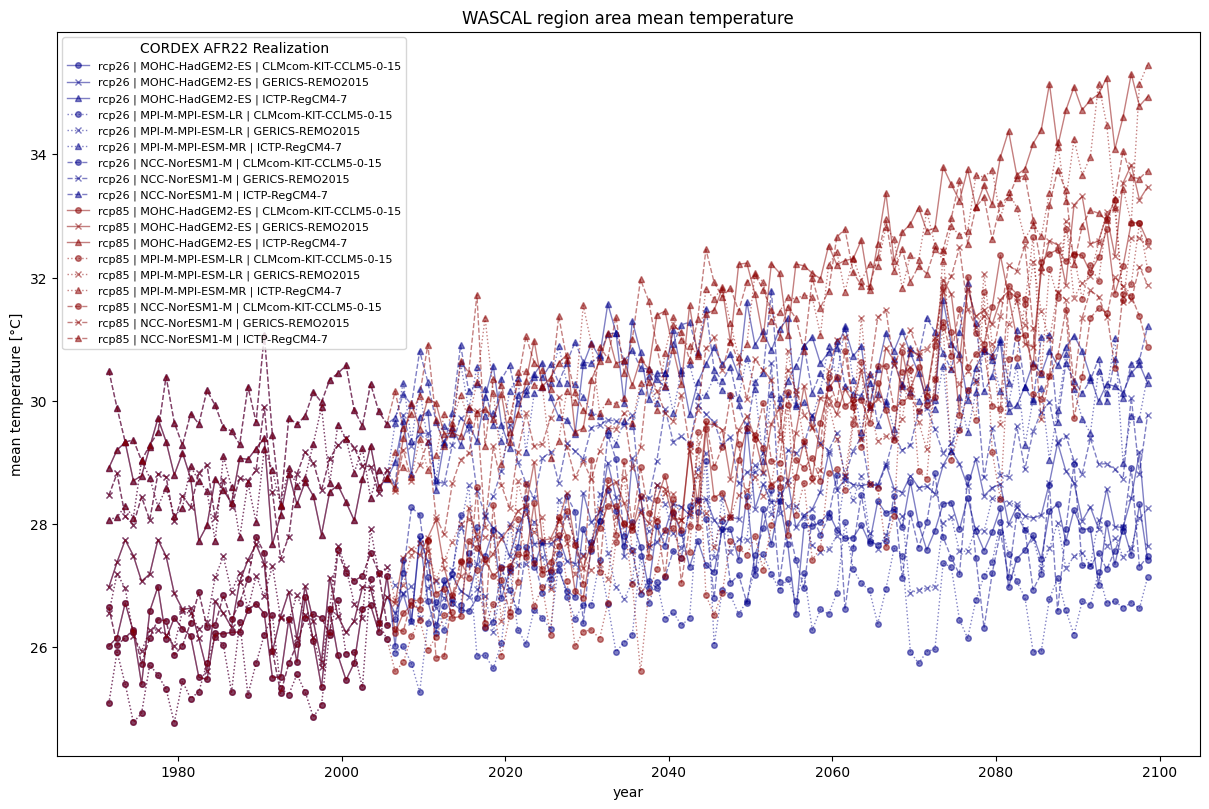

In [10]:
# make plot
line_plot(cut_data,'year', 'mean temperature [°C]','Scenario', outputpath)


Plotting column:  mean temperature [°C]
Saved plot to:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries/line_plot_min_max_TG_year_Burkina_Faso.png


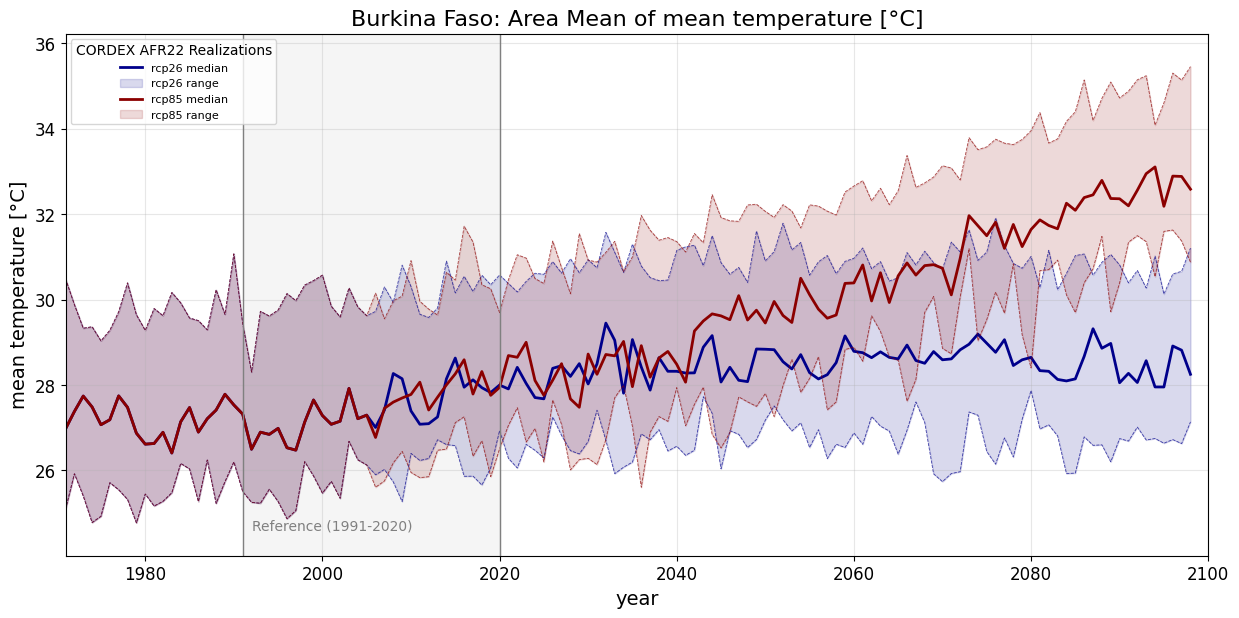

In [22]:
line_plot_min_max(cut_data,'year',longname,index,outputpath,country)


In [23]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
df = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', 'mean temperature [°C]')
df.head()

,realization,year,region,mean temperature [K],ci_name,ci_frequency,standard_name,units,mean temperature [°C],GCM,RCM,scenario,mean_ref,anomaly,running_mean_10yr,running_mean_30yr
0,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,1971,Burkina Faso,299.16830,TG,year,air_temperature,K,26.01830,MOHC-HadGEM2-ES,CLMcom-KIT-CCLM5-0-15,rcp26,26.526432,-0.508132,NaN,NaN
1,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,1972,Burkina Faso,299.30720,TG,year,air_temperature,K,26.15720,MOHC-HadGEM2-ES,CLMcom-KIT-CCLM5-0-15,rcp26,26.526432,-0.369232,NaN,NaN
2,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,1973,Burkina Faso,299.86856,TG,year,air_temperature,K,26.71856,MOHC-HadGEM2-ES,CLMcom-KIT-CCLM5-0-15,rcp26,26.526432,0.192128,NaN,NaN
3,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,1974,Burkina Faso,299.40067,TG,year,air_temperature,K,26.25067,MOHC-HadGEM2-ES,CLMcom-KIT-CCLM5-0-15,rcp26,26.526432,-0.275762,NaN,NaN
4,AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...,1975,Burkina Faso,298.54807,TG,year,air_temperature,K,25.39807,MOHC-HadGEM2-ES,CLMcom-KIT-CCLM5-0-15,rcp26,26.526432,-1.128362,NaN,NaN


                                         realization  year        region  \
0  AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...  1971  Burkina Faso   
1  AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...  1972  Burkina Faso   
2  AFR-22_GERICS_CLMcom-KIT-CCLM5-0-15_MOHC-HadGE...  1973  Burkina Faso   

   mean temperature [K] ci_name ci_frequency    standard_name units  \
0             299.16830      TG         year  air_temperature     K   
1             299.30720      TG         year  air_temperature     K   
2             299.86856      TG         year  air_temperature     K   

   mean temperature [°C]              GCM                    RCM scenario  \
0               26.01830  MOHC-HadGEM2-ES  CLMcom-KIT-CCLM5-0-15    rcp26   
1               26.15720  MOHC-HadGEM2-ES  CLMcom-KIT-CCLM5-0-15    rcp26   
2               26.71856  MOHC-HadGEM2-ES  CLMcom-KIT-CCLM5-0-15    rcp26   

    mean_ref   anomaly  running_mean_10yr  running_mean_30yr  
0  26.526432 -0.508132                

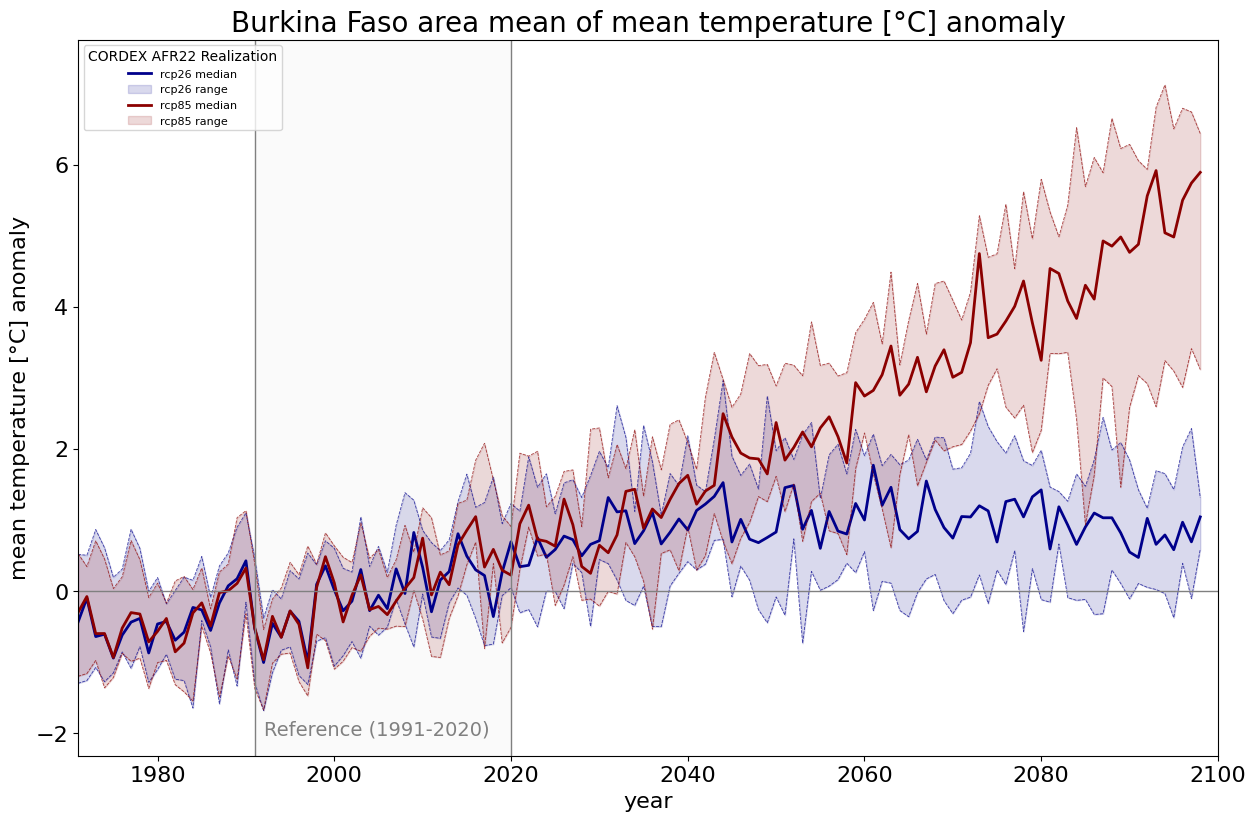

'/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries'

In [29]:
# make line plot of anomaly
# you can chose if you like to group by scenario or not
# you can chose if you like:
    # anomaly or running_mean_10yr or running_mean_30yr

#line_plot_anomaly(df, 'year', 'Temperature [K] anomaly to [1991-2020]', outputpath)
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario', country, longname)
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'model', country, longname)
#line_plot_anomaly(df, 'year', 'running_mean_10yr', outputpath, 'model', country, longname)
#line_plot_anomaly(df, 'year', 'running_mean_30yr', outputpath, 'model', country, longname)
line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname)
outputpath

In [ ]:
# Reste

In [ ]:
df['_RCM'] = df['RCM'].str.split('-').str[1]
df['_RCM'].replace({'KIT': 'CLM'}, inplace=True)
df['_GCM'] = df['GCM'].str.split('-').str[1]
df['_GCM'].replace({'M': 'MPI'}, inplace=True)
#df['_RCM'].unique()
df['realization-short'] = df['_RCM'] + '_' + df['_GCM'] 
df['realization-short'].unique()

/tmp/ipykernel_68491/2795592857.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['_RCM'].replace({'KIT': 'CLM'}, inplace=True)
/tmp/ipykernel_68491/2795592857.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

array(['CLM_HadGEM2', 'CLM_MPI', 'CLM_NorESM1', 'REMO2015_HadGEM2',
       'REMO2015_MPI', 'REMO2015_NorESM1', 'RegCM4_MPI', 'RegCM4_NorESM1',
       'RegCM4_HadGEM2'], dtype=object)

In [66]:
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap, Normalize
# Farben - 8 blau und 8 rot
pcmap = ListedColormap(
    [
        "#08306b",
        "#08519c",
        "#2171b5",
        "#4292c6",
        "#6baed6",
        "#9ecae1",
        "#c6dbef",
        "#deebf7",
        "#fee0d2",
        "#fcbba1",
        "#fc9272",
        "#fb6a4a",
        "#ef3b2c",
        "#cb181d",
        "#a50f15",
        "#67000d",
    ]
)
# linearly normalizes data into the [0.0, 1.0] interval
custom_cmap = LinearSegmentedColormap.from_list('custom_map', pcmap.colors, N=14)
#norm = Normalize(vmin=-2, vmax=6)
#custom_colors = rcp85_data["Temperature [K] anomaly to [1991-2024]"].apply(lambda x: custom_cmap(norm([x]))).tolist()